In [21]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [22]:
df = pd.read_csv("../data/insurance.csv")
df.info()
df.describe([0.1, 0.25, 0.5, 0.75, 0.9]).T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


,count,mean,std,min,10%,25%,50%,75%,90%,max
age,1338.0,39.207025,14.049960,18.0000,19.000000,27.00000,39.000,51.000000,59.0000,64.00000
bmi,1338.0,30.663397,6.098187,15.9600,22.990000,26.29625,30.400,34.693750,38.6195,53.13000
children,1338.0,1.094918,1.205493,0.0000,0.000000,0.00000,1.000,2.000000,3.0000,5.00000
charges,1338.0,13270.422265,12110.011237,1121.8739,2346.533615,4740.28715,9382.033,16639.912515,34831.7197,63770.42801


In [23]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


<Axes: xlabel='age', ylabel='charges'>

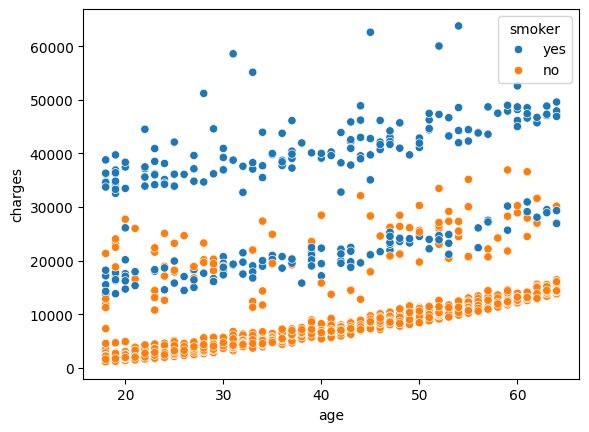

In [24]:
sns.scatterplot(data=df, x="age", y="charges", hue="smoker")

In [26]:
X = df.drop(["charges","region"], axis=1) #independent variable
y = df["charges"] #dependent variable

In [27]:
X.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker'], dtype='object')

In [28]:
X.dtypes

age           int64
sex          object
bmi         float64
children      int64
smoker       object
dtype: object

In [29]:
X["sex"] = X["sex"].map({"male":0, "female":1})
X["smoker"] = X["smoker"].map({"yes":1, "no":0})


In [34]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

In [35]:
y_train.head()

693      2352.96845
1297     4340.44090
634      9391.34600
1022    42211.13820
178      8823.27900
Name: charges, dtype: float64

In [36]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [37]:
y_pred = model.predict(X_test)

In [38]:
y_pred

array([ 8.51676162e+03,  6.89385906e+03,  3.67761988e+04,  9.46438066e+03,
        2.67899225e+04,  1.10936342e+04,  1.49128837e+01,  1.68237415e+04,
        6.43734027e+02,  1.12091522e+04,  2.84914780e+04,  9.31642557e+03,
        5.36756204e+03,  3.85317525e+04,  4.03994299e+04,  3.72400044e+04,
        1.52908425e+04,  3.59824668e+04,  9.28372808e+03,  3.13154472e+04,
        4.26888952e+03,  1.04948927e+04,  2.66379317e+03,  6.45853253e+03,
        1.12164091e+04,  1.24458129e+04,  1.47987228e+04,  5.98242268e+03,
        9.50360619e+03,  2.31859179e+03,  9.43737627e+03,  1.29458564e+04,
        4.58198818e+03,  3.33952812e+03,  4.78782402e+03,  1.25054254e+04,
        2.24235935e+03,  9.10960670e+03,  3.31881458e+04,  3.27197321e+04,
        4.18213700e+03,  4.18988685e+03,  1.44226759e+04,  1.14470784e+04,
        8.92634882e+03,  1.25501051e+04,  5.04542241e+03,  3.46423514e+03,
        3.56618124e+04,  9.27103562e+03,  1.59719021e+04,  2.50117490e+03,
        1.21029904e+04,  

In [39]:
# y= w0 + w1*x1 + w2*x2 + w3*x3 + w4*x4 + w5*x5

model.coef_, model.intercept_

(array([  260.03578967,   -66.06974502,   327.55999306,   434.80431165,
        23628.2381829 ]),
 np.float64(-12234.710618819903))

In [40]:
print("Bias:", model.intercept_)
for feature, coef in zip(X.columns, model.coef_):
    print(f"{feature}: {coef}")

Bias: -12234.710618819903
age: 260.0357896727629
sex: -66.06974502171974
bmi: 327.559993058704
children: 434.80431164736547
smoker: 23628.23818290221


In [41]:

X_test["actual_charges"] = y_test
X_test["predicted_charges"] = y_pred
X_test.head()

,age,sex,bmi,children,smoker,actual_charges,predicted_charges
764,45,1,25.175,2,0,9095.06825,8516.761620
887,36,1,30.020,0,0,5272.17580,6893.859056
890,64,1,26.885,0,1,29330.98315,36776.198772
1293,46,0,25.745,3,0,9301.89355,9464.380662
259,19,0,31.920,0,1,33750.29180,26789.922546


In [42]:
inter = model.intercept_
coefs = model.coef_


X_test["predicted_charges_manual"] = inter + coefs[0]*X_test["age"] + coefs[1]*X_test["sex"] + coefs[2]*X_test["bmi"] + coefs[3]*X_test["children"] + coefs[4]*X_test["smoker"]

In [43]:
X_test.head()

,age,sex,bmi,children,smoker,actual_charges,predicted_charges,predicted_charges_manual
764,45,1,25.175,2,0,9095.06825,8516.761620,8516.761620
887,36,1,30.020,0,0,5272.17580,6893.859056,6893.859056
890,64,1,26.885,0,1,29330.98315,36776.198772,36776.198772
1293,46,0,25.745,3,0,9301.89355,9464.380662,9464.380662
259,19,0,31.920,0,1,33750.29180,26789.922546,26789.922546


In [62]:
#Signed error = actual - predicted
#Absolute error = |actual - predicted|
#mean signed error = mean(actual - predicted)
#mean squared error = mean((actual - predicted)^2)
#mean absolute error = mean(|actual - predicted|)
#median absolute error = median(|actual - predicted|)
#RMSE = sqrt(mean((actual - predicted)^2))
#R2 = 1 - (sum((actual - predicted)^2) / sum((actual - mean(actual))^2))
#adjusted R2 = 1 - (1-R2)*(n-1)/(n-p-1) where n is the number of observations and p is the number of predictors

In [63]:
#mean signed error
mean_signed_error = (X_test["actual_charges"] - X_test["predicted_charges"]).median()
mean_signed_error

np.float64(-1050.630578049484)

In [64]:
median_absolute_error = (X_test["actual_charges"] - X_test["predicted_charges"]).abs().median()
median_absolute_error

np.float64(2748.5459209820674)

In [65]:
rmse = ((X_test["actual_charges"] - X_test["predicted_charges"])**2).mean()**0.5
rmse

np.float64(5952.148688048979)

In [66]:
from sklearn.metrics import r2_score, root_mean_squared_error
r2 = r2_score(X_test["actual_charges"], X_test["predicted_charges"])
r2

0.7652077247609824

In [67]:
y_train_pred = model.predict(X_train)


In [68]:
X_train["actual_charges"] = y_train
X_train["predicted_charges"] = y_train_pred

r2 = r2_score(X_train["actual_charges"], X_train["predicted_charges"])
adjusted_r2 = 1 - (1-r2)*(len(X_train)-1)/(len(X_train)-X_train.shape[1]-1)
adjusted_r2

0.7423662247886349

In [73]:
#Feature engineering
X = df.drop(["charges"], axis=1)
y = df["charges"]

In [ ]:
X = pd.get_dummies(X, columns=["sex", "smoker", "region"], drop_first=True, dtype=int)

KeyError: "['region'] not in index"

In [ ]:
X.head()

,age,bmi,children,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,0,1,0,0,1
1,18,33.770,1,1,0,0,1,0
2,28,33.000,3,1,0,0,1,0
3,33,22.705,0,1,0,1,0,0
4,32,28.880,0,1,0,1,0,0


In [76]:
X["bmi_smoker"] = X["bmi"] * X["smoker_yes"]
X["age_smoker"] = X["age"] * X["smoker_yes"]

In [77]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

In [78]:
model = LinearRegression()
model.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [82]:
model.intercept_, model.coef_

(np.float64(-2390.8489185326744),
 array([ 2.68196287e+02,  2.10152045e+01,  4.91078499e+02, -4.61482575e+02,
        -2.13430719e+04, -5.80317544e+02, -9.54313517e+02, -1.17721971e+03,
         1.47806555e+03, -1.92794891e+00]))

In [83]:
print("Bias:", model.intercept_)
for feature, coef in zip(X.columns, model.coef_):
    print(f"{feature}: {coef}")

Bias: -2390.8489185326744
age: 268.1962874490393
bmi: 21.01520454525142
children: 491.0784993844065
sex_male: -461.4825748681428
smoker_yes: -21343.071923300962
region_northwest: -580.3175444228652
region_southeast: -954.3135167965994
region_southwest: -1177.2197132442816
bmi_smoker: 1478.0655520803534
age_smoker: -1.9279489067509559


In [79]:
r2 = r2_score(y_test, model.predict(X_test))
r2

0.8537528677181383

In [80]:
r2_input = r2_score(y_train, model.predict(X_train))
n = len(X_train)
p = X_train.shape[1]
adjusted_r2_input = 1 - (1-r2_input)*(n-1)/(n-p-1)
adjusted_r2_input

0.8345442108154907

In [81]:
#underfitting: low r2 on train and test data, model is too simple, high bias
#Overfitting: high r2 on train data, low r2 on test data, model is too complex, high variance

print("R2 on test data:", r2)
print("R2 on train data:", r2_input)



R2 on test data: 0.8537528677181383
R2 on train data: 0.8361954661965736


In [36]:

# y = 2x 

x = [1, 2, 3, 4, 5]
y = [2*i for i in x]



In [37]:
# x= 1

#y1 = x
y1 = [i for i in x]

#cost function = 1/2*m sum(predicted - actual)^2

J1 = 1/(2*len(x)) * sum([(y1[i] - y[i])**2 for i in range(len(x))])
J1

5.5

In [38]:
# x = 2

#y2 = 2*x
y2 = [2*i for i in x]

#cost function = 1/2*m sum(predicted - actual)^2

J2 = 1/(2*len(x)) * sum([(y2[i] - y[i])**2 for i in range(len(x))])
J2

0.0

In [40]:
# x=3

y3 = 3*x

#cost function = 1/2*m sum(predicted - actual)^2    

J3 = 1/(2*len(x)) * sum([(y3[i] - y[i])**2 for i in range(len(x))])
J3

5.5

In [41]:
theta = [1, 2, 3]
J_ = [5.5, 0, 5.5]

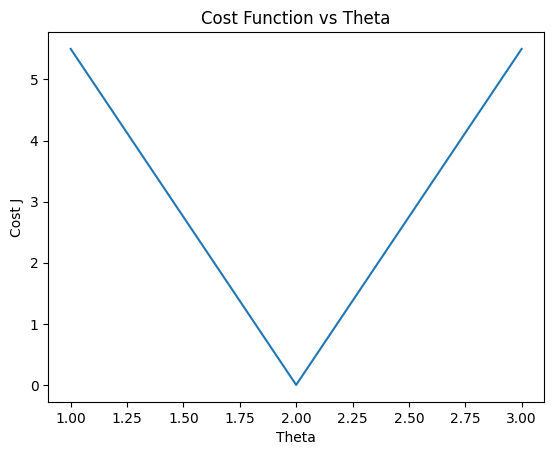

In [42]:
import matplotlib.pyplot as plt

plt.plot(theta, J_)
plt.xlabel('Theta')
plt.ylabel('Cost J')
plt.title('Cost Function vs Theta')
plt.show()

In [11]:
x = [0,1,2,3,4,5]
y = [2*i for i in x]
y1 = [2*i + 3 for i in x]

In [12]:
y

[0, 2, 4, 6, 8, 10]

In [15]:
y1

[3, 5, 7, 9, 11, 13]

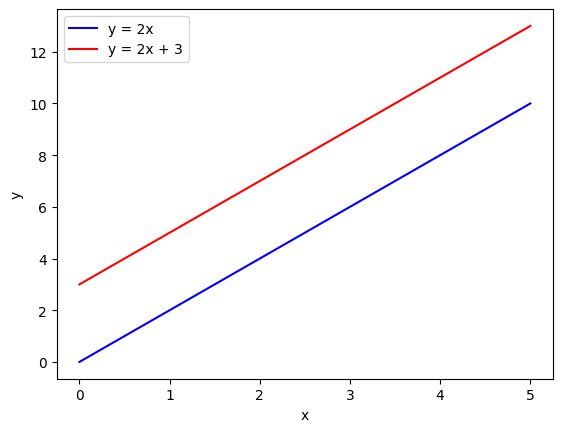

In [16]:
import matplotlib.pyplot as plt

plt.plot(x, y, color='blue', label='y = 2x')
plt.plot(x, y1, color='red', label='y = 2x + 3')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()

In [17]:
# y= 2x 


theta = [1,2,3]

# j = 1/2m sum((predicted - actual)^2) = 1/2m sum((theta*x - y)^2)

y = [2*i for i in x]
err = []

for i in range(len(theta)):
    j = 1/(2*len(x)) * sum([(theta[i]*x[j] - y[j])**2 for j in range(len(x))])
    err.append(j)



In [18]:
err

[4.583333333333333, 0.0, 4.583333333333333]

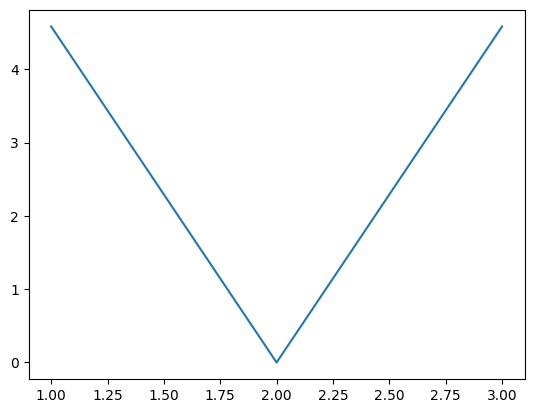

In [19]:
plt.plot(theta, err)

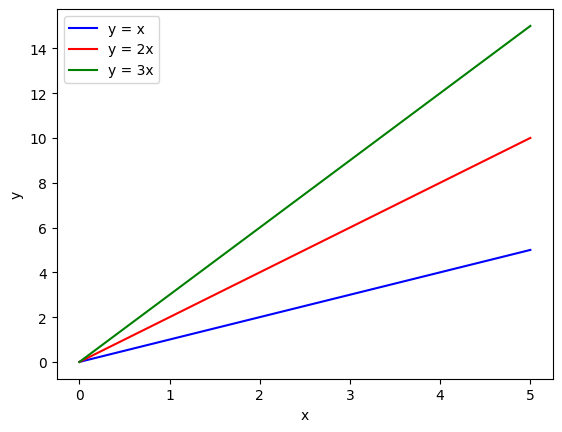

In [20]:
x = [0,1,2,3,4,5]

y = x
y1 = [2*i for i in x]
y2 = [3*i for i in x]


plt.plot(x, y, color='blue', label='y = x')
plt.plot(x, y1, color='red', label='y = 2x')
plt.plot(x, y2, color='green', label='y = 3x')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()